# 13. Can pressure be detected without a human? Supervised classification from event + tracking data

Question: given only what a machine can compute (event timing / passer from the event data, player positions and
velocities from tracking), can a supervised model reproduce the analysts' pressure tags — and does it need the
**possession** (reception → pass) or only the **moment of the pass**?

- Labels: analysts' pass-level pressure tag (P vs N; also any pressure P/A/L vs N).
- Inputs never include a human pressure judgement (the reception tag is excluded).
- Feature sets
  - **moment**: snapshot at the pass frame (nearest distances, defender counts, published metrics, closing speed, direction, speeds, location) — as notebook 05
  - **possession**: exposure between reception and pass from tracking (distance at reception, minimum / mean distance, time and share within 2.74 / 4.57 m, onset, duration) — as notebook 11
- Model: LightGBM, game-grouped 5-fold cross-validation (all predictions come from unseen matches).
- Comparison: ROC-AUC, PR-AUC, accuracy, F1, Cohen's κ; gain tested with a game-level cluster bootstrap.
- Interpretation: SHAP (LightGBM `pred_contrib`), share of importance from moment vs possession features.

In [1]:
import os
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, f1_score, cohen_kappa_score

from football.common import KEY, cv_predict, boot_ci, boot_diff

OUT = os.path.join("..", "outputs")
FIG = os.path.join(OUT, "figs")
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, verbose=-1)
gbm = lambda s: lgb.LGBMClassifier(random_state=s, **LGB_PARAMS)

MOMENT = ["d1", "d2", "d3", "n3", "n5", "andr_sum", "andr_max", "pi_max", "pi_comb", "tti_min",
          "arrival_min", "closing1", "cos1", "speed1", "closing_max", "carrier_speed", "cx", "cy"]
POSSESSION = ["d_start", "d_min", "d_mean", "t_under_274", "share_under_274", "onset_274",
              "t_under_457", "share_under_457", "onset_457", "dur"]

E = pd.read_csv(os.path.join(OUT, "pressure_events.csv.gz"))
X = E.merge(pd.read_csv(os.path.join(OUT, "possession_exposure.csv.gz")), on=KEY)
X["dur"] = X.n_frames / 29.97
print(f"passes with event + tracking features: {len(X):,}")
X.label.value_counts()

passes with event + tracking features: 60,483


label
N    30246
P    22143
L     4615
A     3479
Name: count, dtype: int64

## 1. Train and evaluate (game-grouped CV)

In [2]:
def evaluate(task, pos):
    m = X.label.isin(pos + ["N"])
    D = X[m]
    y, g = D.label.isin(pos).astype(int), D.game_id
    preds = {"distance only (no learning)": -D.d1.to_numpy(),
             "moment": cv_predict(gbm, D[MOMENT].fillna(-1), y, g, seeds=(0,)),
             "moment + possession": cv_predict(gbm, D[MOMENT + POSSESSION].fillna(-1), y, g, seeds=(0,))}
    rows = []
    for name, p in preds.items():
        lo, hi = boot_ci(y, p, roc_auc_score, n=300, groups=g)
        row = dict(task=task, model=name, n=len(D), roc_auc=roc_auc_score(y, p), ci95=f"[{lo:.3f}, {hi:.3f}]",
                   pr_auc=average_precision_score(y, p))
        if name != "distance only (no learning)":
            yhat = (p >= 0.5).astype(int)
            row.update(accuracy=accuracy_score(y, yhat), f1=f1_score(y, yhat), kappa=cohen_kappa_score(y, yhat))
        rows.append(row)
    d, ci, _ = boot_diff(y, preds["moment + possession"], preds["moment"], roc_auc_score, n=300, groups=g)
    print(f"{task}: gain from possession features {d:+.4f} [{ci[0]:+.4f}, {ci[1]:+.4f}]")
    return rows, (D, y, preds)


rows, keep = [], {}
for task, pos in {"P vs N": ["P"], "any (P/A/L) vs N": ["P", "A", "L"]}.items():
    r, keep[task] = evaluate(task, pos)
    rows += r
res = pd.DataFrame(rows).round(3)
res

P vs N: gain from possession features +0.0087 [+0.0072, +0.0104]


any (P/A/L) vs N: gain from possession features +0.0098 [+0.0080, +0.0119]


,task,model,n,roc_auc,ci95,pr_auc,accuracy,f1,kappa
0,P vs N,distance only (no learning),52389,0.890,"[0.878, 0.901]",0.851,NaN,NaN,NaN
1,P vs N,moment,52389,0.913,"[0.903, 0.922]",0.879,0.843,0.810,0.676
2,P vs N,moment + possession,52389,0.922,"[0.912, 0.930]",0.896,0.849,0.816,0.689
3,any (P/A/L) vs N,distance only (no learning),60483,0.871,"[0.860, 0.880]",0.858,NaN,NaN,NaN
4,any (P/A/L) vs N,moment,60483,0.892,"[0.883, 0.900]",0.881,0.814,0.813,0.627
5,any (P/A/L) vs N,moment + possession,60483,0.902,"[0.893, 0.910]",0.898,0.821,0.820,0.642


## 2. Where does the moment-only model fail, and does the possession model fix it?
Passes with the nearest defender 4–12 m away at the pass (outside the 2.74 m guideline), P vs N.

In [3]:
D, y, preds = keep["P vs N"]
far = (D.d1 >= 4).to_numpy() & (D.d1 < 12).to_numpy()
far_rows = [dict(model=k, roc_auc_far=roc_auc_score(y[far], p[far])) for k, p in preds.items()]
print(f"far passes: {far.sum():,}  (P share {y[far].mean():.3f})")
pd.DataFrame(far_rows).round(3)

far passes: 22,514  (P share 0.136)


,model,roc_auc_far
0,distance only (no learning),0.637
1,moment,0.778
2,moment + possession,0.798


## 3. SHAP: importance of moment vs possession features (full fit, P vs N)

In [4]:
cols = MOMENT + POSSESSION
full = gbm(0).fit(D[cols].fillna(-1), y)
contrib = full.predict_proba(D[cols].fillna(-1), pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(0), index=cols).sort_values(ascending=False)
share = (imp / imp.sum()).round(3)
group = pd.Series({"moment": share[MOMENT].sum(), "possession": share[POSSESSION].sum()}).round(3)
display(group)
share.head(12)

moment        0.791
possession    0.210
dtype: float64

d1             0.306
andr_max       0.083
cos1           0.070
arrival_min    0.065
d_start        0.052
dur            0.051
d_min          0.048
cy             0.046
n3             0.043
pi_comb        0.037
speed1         0.025
cx             0.023
dtype: float64

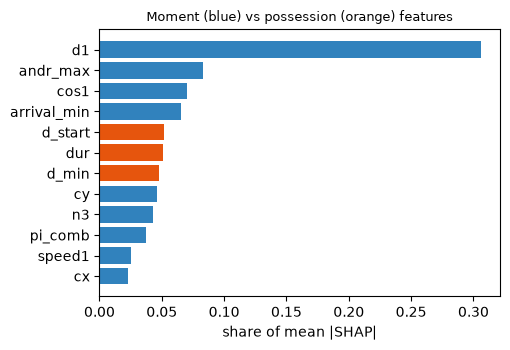

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
top = share.head(12)[::-1]
ax.barh(top.index, top.values, color=["#e6550d" if c in POSSESSION else "#3182bd" for c in top.index])
ax.set_xlabel("share of mean |SHAP|")
ax.set_title("Moment (blue) vs possession (orange) features", fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_classifier_shap.png"), dpi=300)

## 4. Confusion matrices (threshold 0.5)
Rows = analysts' tag, columns = model prediction; cells show counts and the share of each row.

('P vs N', 'moment'): sensitivity 0.791, specificity 0.880, precision 0.829
('P vs N', 'moment + possession'): sensitivity 0.793, specificity 0.890, precision 0.841
('any (P/A/L) vs N', 'moment + possession'): sensitivity 0.813, specificity 0.829, precision 0.826


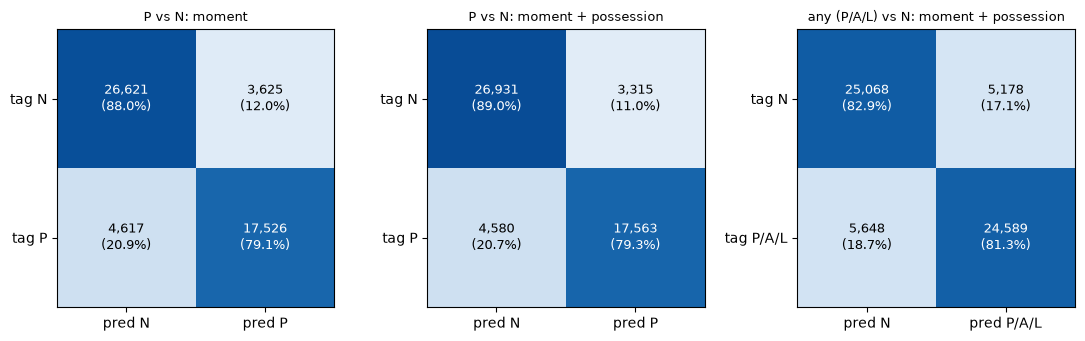

In [6]:
from sklearn.metrics import confusion_matrix

panels = [("P vs N", "moment", ["N", "P"]), ("P vs N", "moment + possession", ["N", "P"]),
          ("any (P/A/L) vs N", "moment + possession", ["N", "P/A/L"])]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
cms = {}
for ax, (task, model, names) in zip(axes, panels):
    D_, y_, p_ = keep[task]
    cm = confusion_matrix(y_, (p_[model] >= 0.5).astype(int))
    cms[(task, model)] = cm
    rate = cm / cm.sum(1, keepdims=True)
    ax.imshow(rate, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({rate[i, j]:.1%})", ha="center", va="center",
                    color="white" if rate[i, j] > 0.6 else "black", fontsize=9)
    ax.set_xticks([0, 1], [f"pred {n}" for n in names]); ax.set_yticks([0, 1], [f"tag {n}" for n in names])
    ax.set_title(f"{task}: {model}", fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_classifier_confusion.png"), dpi=300)
for k, cm in cms.items():
    tn, fp, fn, tp = cm.ravel()
    print(f"{k}: sensitivity {tp / (tp + fn):.3f}, specificity {tn / (tn + fp):.3f}, precision {tp / (tp + fp):.3f}")

## Save

In [7]:
res.to_csv(os.path.join(OUT, "classifier_results.csv"), index=False)
pd.DataFrame(far_rows).to_csv(os.path.join(OUT, "classifier_far.csv"), index=False)
share.to_csv(os.path.join(OUT, "classifier_shap.csv"))
print("saved")

saved
